<a href="https://colab.research.google.com/github/fernandouribeu/analisis_datos/blob/main/Notebook_E2_Preparacion_EDA_Tiempos_Reposicion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E2 · Preparación y EDA de tiempos de reposición

**Fuente esperada:** `BASE_CORTES 12 M.xlsx`  
**Periodo esperado:** noviembre de 2025 a octubre de 2026  
**Pregunta rectora:** ¿Cómo se distribuyen y en qué medida difieren los tiempos de reposición entre comunas de la Región Metropolitana?

El notebook conserva la fuente original, documenta filtros y exclusiones, genera tablas analíticas, desarrolla dos recorridos EDA conectados y exporta una prueba de concepto. Coloque el Excel en la misma carpeta y ejecute **Run All**.

**Sistema visual L2:** `#25251F` texto, `#B43A22` acento, `#7F7D73` serie, `#D8D3C7` soporte, DejaVu Sans.


## 0. Configuración, rutas y trazabilidad

In [ ]:
from pathlib import Path
from datetime import datetime
import hashlib, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display
warnings.filterwarnings("ignore")
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

BASE_DIR = Path('/content/drive/MyDrive/Visualización')
SOURCE_FILE = BASE_DIR / 'BASE_CORTES 12 M.xlsx'
OUTPUT_DIR = BASE_DIR / 'salidas_e2'
OUTPUT_DIR.mkdir(exist_ok=True)
PIPELINE_VERSION = "E2-v1.0"
RUN_TIMESTAMP = datetime.now().isoformat(timespec="seconds")

INK="#25251F"; ACC="#B43A22"; TAUPE="#7F7D73"; LIGHT="#D8D3C7"; MUTED="#66635B"; TEAL="#2C7C83"
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10.5,"text.color":INK,
                     "axes.labelcolor":INK,"xtick.color":INK,"ytick.color":INK,
                     "axes.titleweight":"bold","figure.facecolor":"white","axes.facecolor":"white"})
assert SOURCE_FILE.exists(), f"No se encontró {SOURCE_FILE.name}. Cópielo en {BASE_DIR}"

def sha256_file(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for chunk in iter(lambda:f.read(1024*1024),b""): h.update(chunk)
    return h.hexdigest()
SOURCE_HASH=sha256_file(SOURCE_FILE)
print(SOURCE_FILE.name, PIPELINE_VERSION, RUN_TIMESTAMP, SOURCE_HASH[:16])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE_CORTES 12 M.xlsx E2-v1.0 2026-11-07T18:54:34 ab09ed06f4dd535f


## 1. Carga y validación estructural

La fuente se abre sin modificarla y se verifican las 12 columnas documentadas en L2.

In [ ]:
EXPECTED_COLUMNS=["PERIODO","ANO","MES","ACTIVIDAD","CANT_CLIENTE_AFECTADO","DURACION",
"CORTE_EMERGENCIA","CAUSA","ESTADO","MOTIVO","TIPO","COMUNA"]
df_raw=pd.read_excel(SOURCE_FILE,sheet_name="Hoja1",engine="openpyxl")
df_raw.columns=[str(c).strip().upper() for c in df_raw.columns]
missing=sorted(set(EXPECTED_COLUMNS)-set(df_raw.columns))
assert not missing, f"Faltan columnas: {missing}"
print(f"Filas fuente: {len(df_raw):,} | Columnas: {df_raw.shape[1]}")
display(df_raw.head())

estructura=pd.DataFrame({"columna":df_raw.columns,"tipo":df_raw.dtypes.astype(str).values,
"no_nulos":df_raw.notna().sum().values,"nulos":df_raw.isna().sum().values,
"pct_nulos":(df_raw.isna().mean().values*100).round(2),"unicos":df_raw.nunique(dropna=True).values})
display(estructura)


Filas fuente: 2,416 | Columnas: 12


,PERIODO,ANO,MES,ACTIVIDAD,CANT_CLIENTE_AFECTADO,DURACION,CORTE_EMERGENCIA,CAUSA,ESTADO,MOTIVO,TIPO,COMUNA
0,202610,2026,10,CORTE DE SUMINISTRO,43.0,7.00,True,FALLA DE MATRIZ,REALIZADO,FALLA MATRIZ,EMERGENCIA: FALLA INFRAESTRUCTURA,SAN BERNARDO
1,202610,2026,10,CORTE DE SUMINISTRO,260.0,3.33,True,FALLA DE MATRIZ,REALIZADO,FALLA MATRIZ,EMERGENCIA: FALLA INFRAESTRUCTURA,PUENTE ALTO
2,202610,2026,10,CORTE DE SUMINISTRO,201.0,1.42,True,FALLA DE MATRIZ,REALIZADO,FALLA MATRIZ,EMERGENCIA: FALLA INFRAESTRUCTURA,LA FLORIDA
3,202610,2026,10,CORTE DE SUMINISTRO,116.0,5.00,True,FALLA DE MATRIZ,REALIZADO,FALLA MATRIZ,EMERGENCIA: FALLA INFRAESTRUCTURA,CONCHALÍ
4,202610,2026,10,CORTE DE SUMINISTRO,29.0,4.00,True,FALLA DE MATRIZ,REALIZADO,FALLA MATRIZ,EMERGENCIA: FALLA INFRAESTRUCTURA,MACUL


,columna,tipo,no_nulos,nulos,pct_nulos,unicos
0,PERIODO,int64,2416,0,0.00,13
1,ANO,int64,2416,0,0.00,2
2,MES,int64,2416,0,0.00,12
3,ACTIVIDAD,object,2416,0,0.00,2
4,CANT_CLIENTE_AFECTADO,float64,2414,2,0.08,725
5,DURACION,float64,2415,1,0.04,466
6,CORTE_EMERGENCIA,bool,2416,0,0.00,2
7,CAUSA,object,2416,0,0.00,37
8,ESTADO,object,2416,0,0.00,1
9,MOTIVO,object,2416,0,0.00,13


## 2. Normalización y controles de calidad

Los valores no convertibles quedan como ausentes. Un dato ausente no se reemplaza por cero.

In [ ]:
df_stage=df_raw.copy()
for col in ["ACTIVIDAD","CAUSA","ESTADO","MOTIVO","TIPO","COMUNA"]:
    df_stage[col]=(df_stage[col].astype("string").str.strip().str.upper()
                   .replace({"":pd.NA,"NAN":pd.NA,"NONE":pd.NA}))
for col in ["PERIODO","ANO","MES","CANT_CLIENTE_AFECTADO","DURACION"]:
    df_stage[col]=pd.to_numeric(df_stage[col],errors="coerce")
map_emerg={"T":True,"TRUE":True,"1":True,"SI":True,"SÍ":True,
           "F":False,"FALSE":False,"0":False,"NO":False}
df_stage["CORTE_EMERGENCIA_NORMALIZADO"]=(df_stage["CORTE_EMERGENCIA"].astype("string")
    .str.strip().str.upper().map(map_emerg))
periodo_str=df_stage["PERIODO"].round().astype("Int64").astype("string")
df_stage["FECHA_MES"]=pd.to_datetime(periodo_str,format="%Y%m",errors="coerce")
df_stage["ID_FILA_HASH"]=pd.util.hash_pandas_object(
    df_stage[EXPECTED_COLUMNS].astype("string"),index=False).astype("uint64").astype("string")

calidad=pd.DataFrame({"control":["DURACION ausente/no numérica","PERIODO inválido","COMUNA ausente",
"ESTADO ausente","CORTE_EMERGENCIA no reconocido"],"registros":[df_stage.DURACION.isna().sum(),
 df_stage.FECHA_MES.isna().sum(),df_stage.COMUNA.isna().sum(),df_stage.ESTADO.isna().sum(),
 df_stage.CORTE_EMERGENCIA_NORMALIZADO.isna().sum()]})
display(calidad)


,control,registros
0,DURACION ausente/no numérica,1
1,PERIODO inválido,0
2,COMUNA ausente,0
3,ESTADO ausente,0
4,CORTE_EMERGENCIA no reconocido,0


## 3. Funnel, filtros y deduplicación

Reglas: `ESTADO = REALIZADO`, duración disponible y mayor que cero, comuna disponible, periodo válido y eliminación de duplicados exactos en las 12 columnas originales. No se imputan valores. Los extremos válidos se conservan.

In [ ]:
duplicado_exacto=df_stage.duplicated(subset=EXPECTED_COLUMNS,keep="first")
steps=[df_stage]
steps.append(steps[-1].loc[steps[-1].ESTADO.eq("REALIZADO")].copy())
steps.append(steps[-1].loc[steps[-1].DURACION.notna()].copy())
steps.append(steps[-1].loc[steps[-1].DURACION.gt(0)].copy())
steps.append(steps[-1].loc[steps[-1].COMUNA.notna()].copy())
steps.append(steps[-1].loc[steps[-1].FECHA_MES.notna()].copy())
steps.append(steps[-1].drop_duplicates(subset=EXPECTED_COLUMNS,keep="first").copy())
labels=["Fuente original","ESTADO = REALIZADO","DURACION disponible","DURACION > 0",
        "COMUNA disponible","PERIODO válido","Sin duplicados exactos"]
funnel=pd.DataFrame({"paso":labels,"registros_restantes":[len(x) for x in steps]})
funnel["excluidos_en_paso"]=funnel.registros_restantes.shift(1).sub(funnel.registros_restantes).fillna(0).astype(int)
df_clean=steps[-1]
df_clean["TIPO_CORTE"]=np.select([df_clean.CORTE_EMERGENCIA_NORMALIZADO.eq(True),
 df_clean.CORTE_EMERGENCIA_NORMALIZADO.eq(False)],["Emergencia","Programado"],default="No informado")
df_clean["EVENTO_PROLONGADO_12H"]=df_clean.DURACION.ge(12)
display(funnel)
print(f"Base final: {len(df_clean):,} | Duplicados exactos fuente: {duplicado_exacto.sum():,}")


,paso,registros_restantes,excluidos_en_paso
0,Fuente original,2416,0
1,ESTADO = REALIZADO,2416,0
2,DURACION disponible,2415,1
3,DURACION > 0,2415,0
4,COMUNA disponible,2415,0
5,PERIODO válido,2415,0
6,Sin duplicados exactos,2323,92


Base final: 2,323 | Duplicados exactos fuente: 92


## 4. Universo oficial y controles

In [ ]:
universo=pd.Series({"registros_originales":len(df_raw),"registros_analizados":len(df_clean),
"duplicados_exactos_fuente":int(duplicado_exacto.sum()),"comunas":int(df_clean.COMUNA.nunique()),
"meses":int(df_clean.FECHA_MES.nunique()),"fecha_inicio":df_clean.FECHA_MES.min().strftime("%Y-%m"),
"fecha_fin":df_clean.FECHA_MES.max().strftime("%Y-%m"),"mediana_h":round(df_clean.DURACION.median(),2),
"promedio_h":round(df_clean.DURACION.mean(),2),"q1_h":round(df_clean.DURACION.quantile(.25),2),
"q3_h":round(df_clean.DURACION.quantile(.75),2),"max_h":round(df_clean.DURACION.max(),2),
"eventos_12h_o_mas":int(df_clean.EVENTO_PROLONGADO_12H.sum()),
"pct_eventos_12h_o_mas":round(df_clean.EVENTO_PROLONGADO_12H.mean()*100,2)})
display(universo.to_frame("valor"))
meses=pd.DatetimeIndex(sorted(df_clean.FECHA_MES.dropna().unique()))
controles={"12_meses":df_clean.FECHA_MES.nunique()==12,
"meses_contiguos":meses.equals(pd.date_range(meses.min(),meses.max(),freq="MS")),
"solo_duraciones_positivas":df_clean.DURACION.gt(0).all(),"solo_realizados":df_clean.ESTADO.eq("REALIZADO").all(),
"sin_duplicados_exactos":~df_clean.duplicated(subset=EXPECTED_COLUMNS).any(),"sin_comuna_nula":df_clean.COMUNA.notna().all()}
display(pd.Series(controles,name="resultado"))


,valor
registros_originales,2416
registros_analizados,2323
duplicados_exactos_fuente,92
comunas,49
meses,13
fecha_inicio,2025-10
fecha_fin,2026-10
mediana_h,4.58
promedio_h,5.81
q1_h,2.56


,resultado
12_meses,False
meses_contiguos,True
solo_duraciones_positivas,True
solo_realizados,True
sin_duplicados_exactos,True
sin_comuna_nula,True


## 5. Tablas analíticas

In [ ]:
def q1(s): return s.quantile(.25)
def q3(s): return s.quantile(.75)
resumen_comuna=df_clean.groupby("COMUNA",as_index=False).agg(n_eventos=("DURACION","size"),
 duracion_promedio_h=("DURACION","mean"),duracion_mediana_h=("DURACION","median"),q1_h=("DURACION",q1),
 q3_h=("DURACION",q3),max_h=("DURACION","max"),clientes_afectados_registrados=("CANT_CLIENTE_AFECTADO","sum"),
 n_eventos_12h_o_mas=("EVENTO_PROLONGADO_12H","sum"),proporcion_12h_o_mas=("EVENTO_PROLONGADO_12H","mean"))
resumen_comuna["iqr_h"]=resumen_comuna.q3_h-resumen_comuna.q1_h
resumen_comuna["porcentaje_eventos"]=resumen_comuna.n_eventos/len(df_clean)

resumen_mes=df_clean.groupby("FECHA_MES",as_index=False).agg(n_eventos=("DURACION","size"),
 duracion_promedio_h=("DURACION","mean"),duracion_mediana_h=("DURACION","median"),q1_h=("DURACION",q1),
 q3_h=("DURACION",q3),n_eventos_12h_o_mas=("EVENTO_PROLONGADO_12H","sum"),
 proporcion_12h_o_mas=("EVENTO_PROLONGADO_12H","mean"))
resumen_mes["iqr_h"]=resumen_mes.q3_h-resumen_mes.q1_h
resumen_mes["periodo"]=resumen_mes.FECHA_MES.dt.strftime("%Y-%m")

resumen_tipo=df_clean.groupby("TIPO_CORTE",as_index=False).agg(n_eventos=("DURACION","size"),
 duracion_promedio_h=("DURACION","mean"),duracion_mediana_h=("DURACION","median"),q1_h=("DURACION",q1),
 q3_h=("DURACION",q3),proporcion_12h_o_mas=("EVENTO_PROLONGADO_12H","mean"))
resumen_tipo["iqr_h"]=resumen_tipo.q3_h-resumen_tipo.q1_h
display(resumen_comuna.sort_values("n_eventos",ascending=False).head(12),resumen_mes,resumen_tipo)


,COMUNA,n_eventos,duracion_promedio_h,duracion_mediana_h,q1_h,q3_h,max_h,clientes_afectados_registrados,n_eventos_12h_o_mas,proporcion_12h_o_mas,iqr_h,porcentaje_eventos
34,PUENTE ALTO,181,4.956961,4.63,2.7500,6.0000,36.00,129177.0,4,0.022099,3.2500,0.077916
14,LA FLORIDA,152,5.595197,4.46,3.2075,6.0250,38.00,152840.0,8,0.052632,2.8175,0.065433
19,LAS CONDES,125,7.030240,5.83,3.4200,9.3300,32.08,31538.0,13,0.104000,5.9100,0.053810
39,SAN BERNARDO,120,4.814167,3.33,1.9800,5.8525,40.00,143874.0,4,0.033333,3.8725,0.051657
30,PEÑALOLÉN,117,5.799573,5.25,2.6200,7.7500,30.50,72814.0,8,0.068376,5.1300,0.050366
20,LO BARNECHEA,94,7.017128,6.25,3.5200,9.6475,28.00,30624.0,8,0.085106,6.1275,0.040465
44,SANTIAGO,83,5.250602,3.70,2.4150,6.8300,27.10,40347.0,6,0.072289,4.4150,0.035730
5,CONCHALÍ,81,6.695309,5.93,3.2500,9.0000,14.67,32150.0,13,0.160494,5.7500,0.034869
37,RECOLETA,72,6.730417,6.00,3.1525,9.4250,31.50,16231.0,8,0.111111,6.2725,0.030994
36,QUINTA NORMAL,69,5.059275,3.83,2.5700,7.0000,14.75,16189.0,4,0.057971,4.4300,0.029703


,FECHA_MES,n_eventos,duracion_promedio_h,duracion_mediana_h,q1_h,q3_h,n_eventos_12h_o_mas,proporcion_12h_o_mas,iqr_h,periodo
0,2025-10-01,178,5.535674,4.900,2.7875,7.1650,11,0.061798,4.3775,2025-10
1,2025-11-01,191,6.399215,5.170,2.6700,8.0000,16,0.083770,5.3300,2025-11
2,2025-12-01,162,5.072160,3.750,2.5200,6.5600,10,0.061728,4.0400,2025-12
3,2026-01-01,173,5.771329,4.880,2.3300,7.5800,13,0.075145,5.2500,2026-01
4,2026-02-01,183,5.686120,5.080,2.8750,7.2500,11,0.060109,4.3750,2026-02
5,2026-03-01,223,5.506547,4.580,2.7500,6.8200,15,0.067265,4.0700,2026-03
6,2026-04-01,182,5.392198,5.100,2.5000,7.4575,9,0.049451,4.9575,2026-04
7,2026-05-01,219,5.233105,4.250,2.5000,7.2250,14,0.063927,4.7250,2026-05
8,2026-06-01,198,8.529394,4.375,2.3525,8.4575,32,0.161616,6.1050,2026-06
9,2026-07-01,201,5.424826,4.830,2.8300,7.2500,9,0.044776,4.4200,2026-07


,TIPO_CORTE,n_eventos,duracion_promedio_h,duracion_mediana_h,q1_h,q3_h,proporcion_12h_o_mas,iqr_h
0,Emergencia,1794,4.573796,3.50,2.17,5.75,0.036232,3.58
1,Programado,529,9.983648,8.33,6.00,11.20,0.192817,5.20


# EDA 1 · ¿Las diferencias entre comunas se mantienen al controlar el tipo de corte?

Primero se comparan mediana e IQR en las 12 comunas con mayor volumen. Después se separan emergencias y programados. Solo se interpretan asociaciones descriptivas.

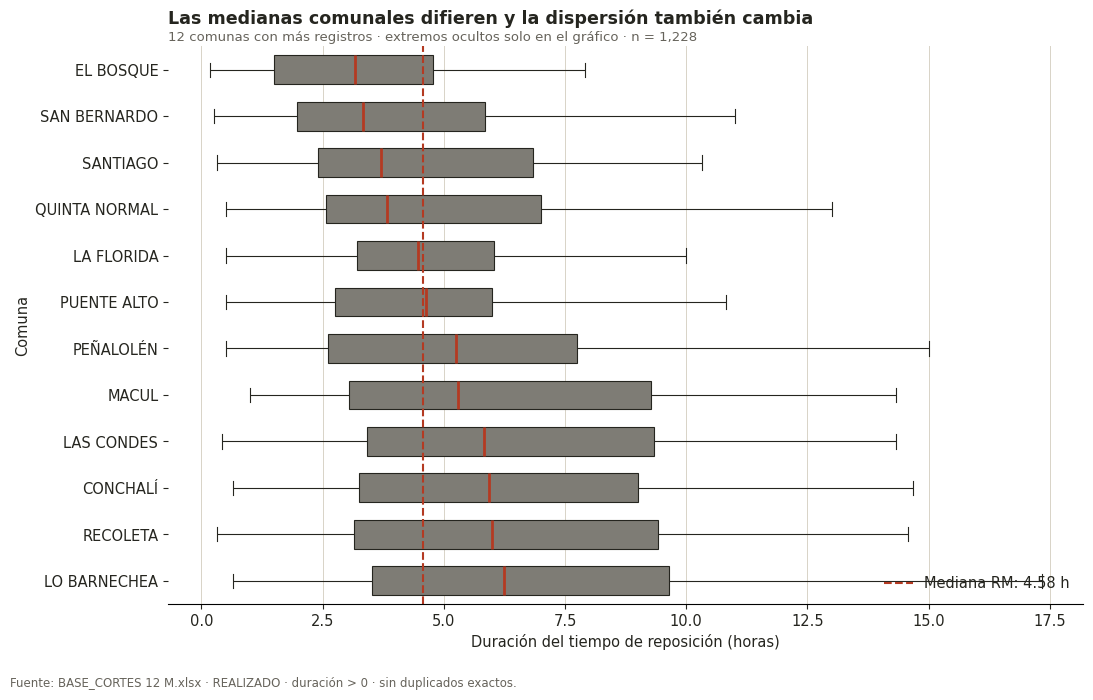

In [ ]:
top_comunas=resumen_comuna.nlargest(12,"n_eventos").COMUNA.tolist()
plot_df=df_clean[df_clean.COMUNA.isin(top_comunas)].copy()
orden=plot_df.groupby("COMUNA").DURACION.median().sort_values().index.tolist()
mediana_rm=df_clean.DURACION.median()
fig,ax=plt.subplots(figsize=(11,7))
sns.boxplot(data=plot_df,y="COMUNA",x="DURACION",order=orden,color=TAUPE,width=.62,showfliers=False,
 boxprops={"edgecolor":INK,"linewidth":.8},whiskerprops={"color":INK,"linewidth":.8},
 capprops={"color":INK,"linewidth":.8},medianprops={"color":ACC,"linewidth":2},ax=ax)
ax.axvline(mediana_rm,color=ACC,ls="--",lw=1.5,label=f"Mediana RM: {mediana_rm:.2f} h")
ax.set_title("Las medianas comunales difieren y la dispersión también cambia",loc="left",pad=16)
ax.text(0,1.01,f"12 comunas con más registros · extremos ocultos solo en el gráfico · n = {len(plot_df):,}",
 transform=ax.transAxes,color=MUTED,fontsize=9.5)
ax.set(xlabel="Duración del tiempo de reposición (horas)",ylabel="Comuna")
ax.grid(axis="x",color=LIGHT,lw=.7); ax.grid(axis="y",visible=False); ax.spines[["top","right","left"]].set_visible(False)
ax.legend(frameon=False,loc="lower right")
fig.text(.01,.01,"Fuente: BASE_CORTES 12 M.xlsx · REALIZADO · duración > 0 · sin duplicados exactos.",fontsize=8.5,color=MUTED)
plt.tight_layout(rect=[0,.04,1,1]); plt.savefig(OUTPUT_DIR/"eda1_boxplot_comunas.png",dpi=220,bbox_inches="tight",facecolor="white"); plt.show()


,COMUNA,TIPO_CORTE,n,mediana_h,q1_h,q3_h,iqr_h
0,CONCHALÍ,Emergencia,65,5.030,3.1700,6.4200,3.2500
2,EL BOSQUE,Emergencia,60,2.670,1.3575,3.7700,2.4125
4,LA FLORIDA,Emergencia,113,3.500,2.6700,5.3300,2.6600
5,LA FLORIDA,Programado,39,7.500,5.7500,11.2500,5.5000
6,LAS CONDES,Emergencia,100,5.150,2.6725,7.4400,4.7675
7,LAS CONDES,Programado,25,10.000,9.1700,12.0000,2.8300
8,LO BARNECHEA,Emergencia,71,5.230,2.8600,8.4200,5.5600
9,LO BARNECHEA,Programado,23,9.500,9.1850,9.8000,0.6150
10,MACUL,Emergencia,49,4.530,2.6700,5.8300,3.1600
12,PEÑALOLÉN,Emergencia,89,4.170,2.0800,6.9200,4.8400


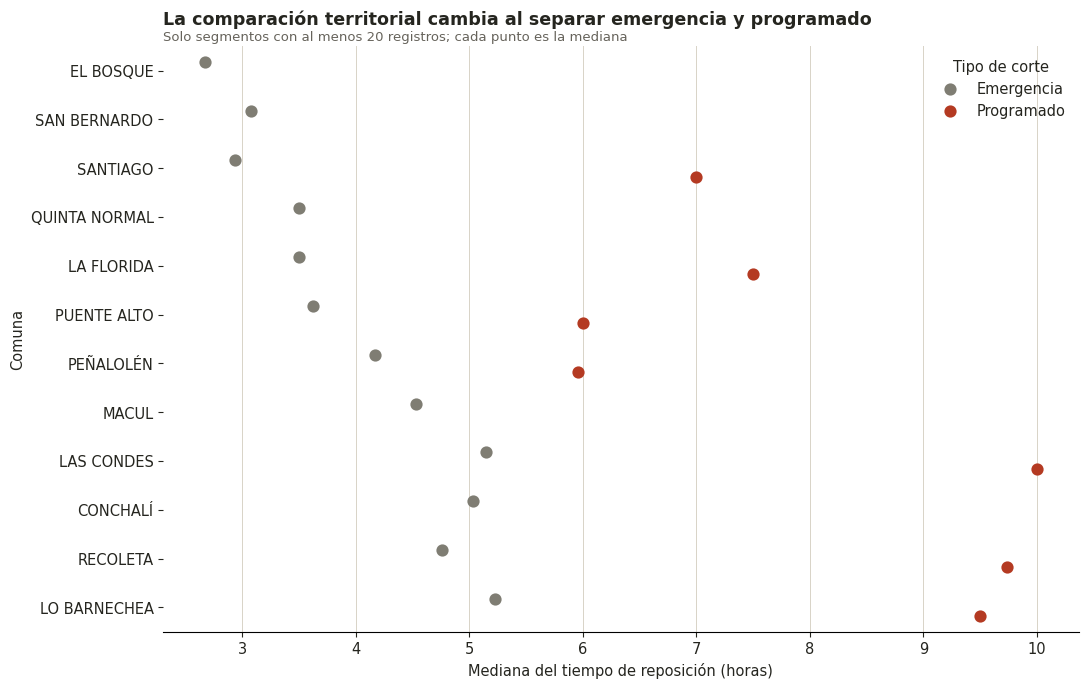

In [ ]:
segmento=plot_df.groupby(["COMUNA","TIPO_CORTE"],as_index=False).agg(n=("DURACION","size"),
 mediana_h=("DURACION","median"),q1_h=("DURACION",q1),q3_h=("DURACION",q3))
segmento["iqr_h"]=segmento.q3_h-segmento.q1_h
segmento_valido=segmento[segmento.n>=20].copy()
display(segmento_valido.sort_values(["COMUNA","TIPO_CORTE"]))
fig,ax=plt.subplots(figsize=(11,7))
sns.pointplot(data=segmento_valido,y="COMUNA",x="mediana_h",hue="TIPO_CORTE",order=orden,dodge=.35,
 join=False,palette={"Emergencia":TAUPE,"Programado":ACC,"No informado":TEAL},ax=ax)
ax.set_title("La comparación territorial cambia al separar emergencia y programado",loc="left",pad=16)
ax.text(0,1.01,"Solo segmentos con al menos 20 registros; cada punto es la mediana",transform=ax.transAxes,color=MUTED,fontsize=9.5)
ax.set(xlabel="Mediana del tiempo de reposición (horas)",ylabel="Comuna")
ax.grid(axis="x",color=LIGHT,lw=.7); ax.grid(axis="y",visible=False); ax.spines[["top","right","left"]].set_visible(False)
ax.legend(title="Tipo de corte",frameon=False)
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda1_comuna_tipo.png",dpi=220,bbox_inches="tight",facecolor="white"); plt.show()


# EDA 2 · ¿Los meses con mayor mediana también presentan más dispersión o eventos prolongados?

Se contrasta mediana, IQR, promedio y proporción de eventos de 12 horas o más para comprobar si el patrón es general o depende de extremos.

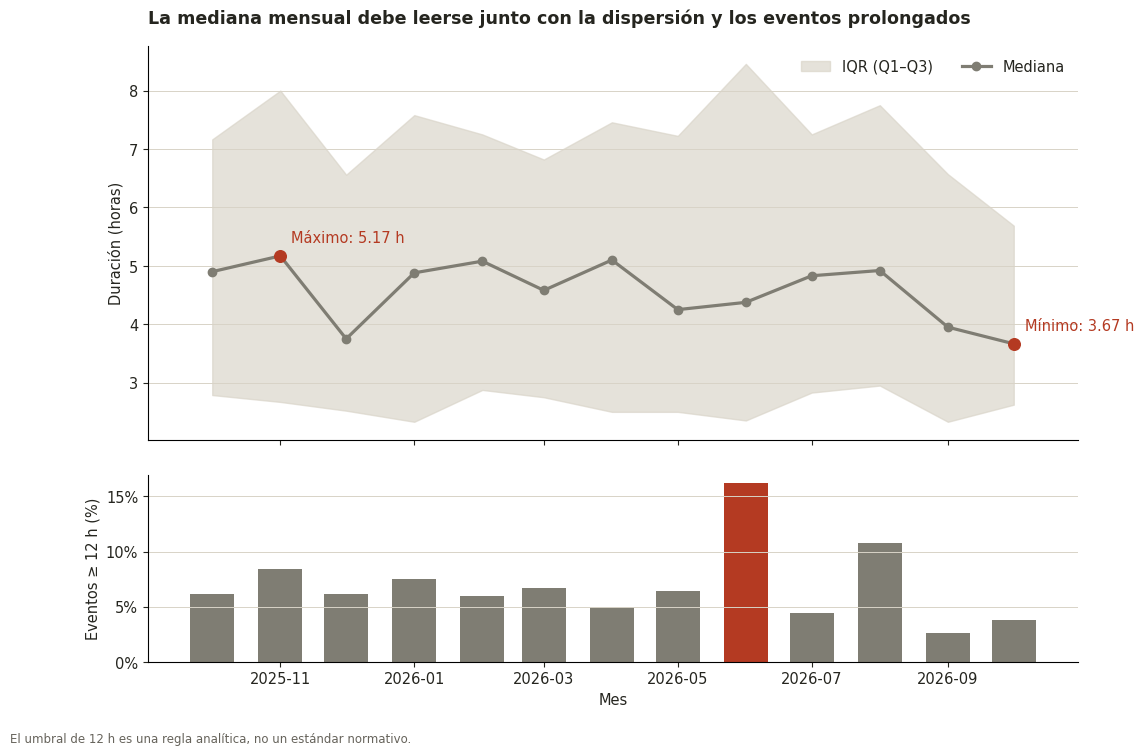

In [ ]:
x=resumen_mes.FECHA_MES
fig,(ax1,ax2)=plt.subplots(2,1,figsize=(12,8),sharex=True,gridspec_kw={"height_ratios":[2.1,1],"hspace":.12})
ax1.fill_between(x,resumen_mes.q1_h,resumen_mes.q3_h,color=LIGHT,alpha=.65,label="IQR (Q1–Q3)")
ax1.plot(x,resumen_mes.duracion_mediana_h,color=TAUPE,lw=2.3,marker="o",label="Mediana")
imin=resumen_mes.duracion_mediana_h.idxmin(); imax=resumen_mes.duracion_mediana_h.idxmax()
for idx,label in [(imin,"Mínimo"),(imax,"Máximo")]:
 r=resumen_mes.loc[idx]; ax1.scatter(r.FECHA_MES,r.duracion_mediana_h,s=70,color=ACC,zorder=5)
 ax1.annotate(f"{label}: {r.duracion_mediana_h:.2f} h",(r.FECHA_MES,r.duracion_mediana_h),xytext=(8,10),textcoords="offset points",color=ACC)
ax1.set_title("La mediana mensual debe leerse junto con la dispersión y los eventos prolongados",loc="left",pad=16)
ax1.set_ylabel("Duración (horas)"); ax1.grid(axis="y",color=LIGHT,lw=.7); ax1.spines[["top","right"]].set_visible(False); ax1.legend(frameon=False,ncol=2)
ax2.bar(x,resumen_mes.proporcion_12h_o_mas*100,color=TAUPE,width=20)
ip=resumen_mes.proporcion_12h_o_mas.idxmax(); ax2.bar(resumen_mes.loc[ip,"FECHA_MES"],resumen_mes.loc[ip,"proporcion_12h_o_mas"]*100,color=ACC,width=20)
ax2.set(ylabel="Eventos ≥ 12 h (%)",xlabel="Mes"); ax2.yaxis.set_major_formatter(mtick.PercentFormatter(100,0)); ax2.grid(axis="y",color=LIGHT,lw=.7); ax2.spines[["top","right"]].set_visible(False)
fig.text(.01,.01,"El umbral de 12 h es una regla analítica, no un estándar normativo.",fontsize=8.5,color=MUTED)
plt.tight_layout(rect=[0,.04,1,1]); plt.savefig(OUTPUT_DIR/"eda2_serie_mensual.png",dpi=220,bbox_inches="tight",facecolor="white"); plt.show()


,periodo,n_eventos,duracion_mediana_h,duracion_promedio_h,q1_h,q3_h,iqr_h,proporcion_12h_o_mas,brecha_promedio_mediana_h
0,2025-10,178,4.900,5.535674,2.7875,7.1650,4.3775,0.061798,0.635674
1,2025-11,191,5.170,6.399215,2.6700,8.0000,5.3300,0.083770,1.229215
2,2025-12,162,3.750,5.072160,2.5200,6.5600,4.0400,0.061728,1.322160
3,2026-01,173,4.880,5.771329,2.3300,7.5800,5.2500,0.075145,0.891329
4,2026-02,183,5.080,5.686120,2.8750,7.2500,4.3750,0.060109,0.606120
5,2026-03,223,4.580,5.506547,2.7500,6.8200,4.0700,0.067265,0.926547
6,2026-04,182,5.100,5.392198,2.5000,7.4575,4.9575,0.049451,0.292198
7,2026-05,219,4.250,5.233105,2.5000,7.2250,4.7250,0.063927,0.983105
8,2026-06,198,4.375,8.529394,2.3525,8.4575,6.1050,0.161616,4.154394
9,2026-07,201,4.830,5.424826,2.8300,7.2500,4.4200,0.044776,0.594826


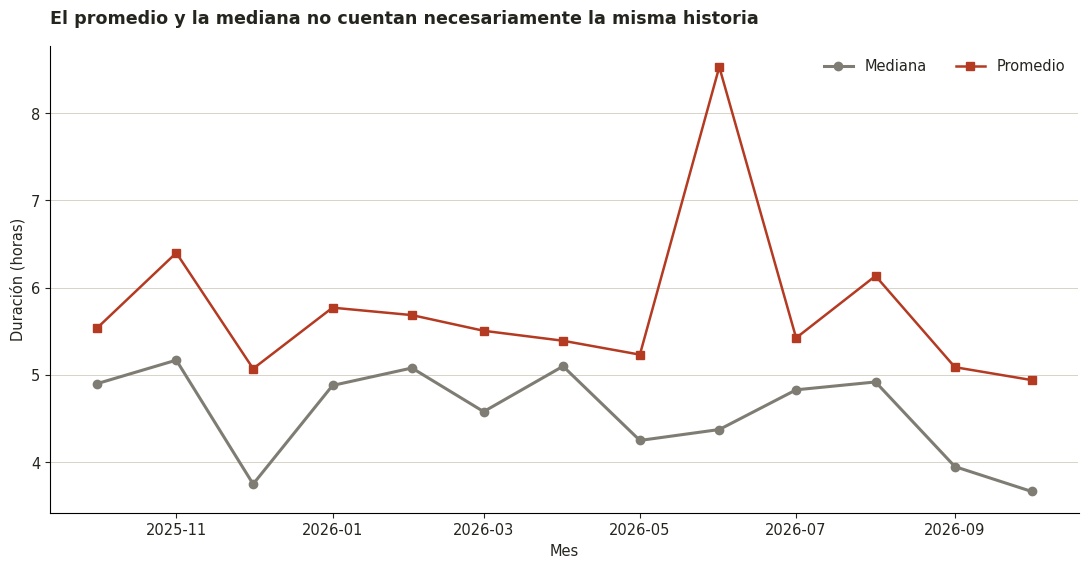

In [ ]:
contraste_mes=resumen_mes[["periodo","n_eventos","duracion_mediana_h","duracion_promedio_h","q1_h","q3_h","iqr_h","proporcion_12h_o_mas"]].copy()
contraste_mes["brecha_promedio_mediana_h"]=contraste_mes.duracion_promedio_h-contraste_mes.duracion_mediana_h
display(contraste_mes)
fig,ax=plt.subplots(figsize=(11,5.8))
ax.plot(x,resumen_mes.duracion_mediana_h,color=TAUPE,lw=2.2,marker="o",label="Mediana")
ax.plot(x,resumen_mes.duracion_promedio_h,color=ACC,lw=1.8,marker="s",label="Promedio")
ax.set_title("El promedio y la mediana no cuentan necesariamente la misma historia",loc="left",pad=16)
ax.set(xlabel="Mes",ylabel="Duración (horas)"); ax.grid(axis="y",color=LIGHT,lw=.7); ax.spines[["top","right"]].set_visible(False); ax.legend(frameon=False,ncol=2)
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda2_promedio_vs_mediana.png",dpi=220,bbox_inches="tight",facecolor="white"); plt.show()


## 6. Sensibilidad del umbral de eventos prolongados

Se comparan 8, 12 y 24 horas en comunas con al menos 30 registros para comprobar si el ranking depende de una sola decisión.

In [ ]:
min_n=30; umbrales=[8,12,24]
validas=resumen_comuna.loc[resumen_comuna.n_eventos>=min_n,"COMUNA"]
sens_df=df_clean[df_clean.COMUNA.isin(validas)].copy(); partes=[]
for u in umbrales:
 a=(sens_df.assign(supera=lambda d:d.DURACION.ge(u)).groupby("COMUNA",as_index=False)
    .agg(n=("DURACION","size"),proporcion=("supera","mean"))); a["umbral_h"]=u; partes.append(a)
sensibilidad=pd.concat(partes,ignore_index=True)
ranking=sensibilidad.pivot(index="COMUNA",columns="umbral_h",values="proporcion"); ranking.columns=[f"prop_ge_{c}h" for c in ranking.columns]; ranking=ranking.reset_index()
display(ranking.sort_values("prop_ge_12h",ascending=False).head(15))


,COMUNA,prop_ge_8h,prop_ge_12h,prop_ge_24h
30,VITACURA,0.473684,0.228070,0.017544
5,HUECHURABA,0.244444,0.177778,0.044444
10,LA REINA,0.418605,0.162791,0.046512
2,CONCHALÍ,0.296296,0.160494,0.000000
27,SAN RAMÓN,0.166667,0.133333,0.100000
26,SAN JOAQUÍN,0.181818,0.121212,0.030303
0,BUIN,0.272727,0.121212,0.030303
23,RECOLETA,0.333333,0.111111,0.013889
31,ÑUÑOA,0.400000,0.109091,0.000000
11,LAS CONDES,0.320000,0.104000,0.040000


## 7. Prueba de concepto visual integrada

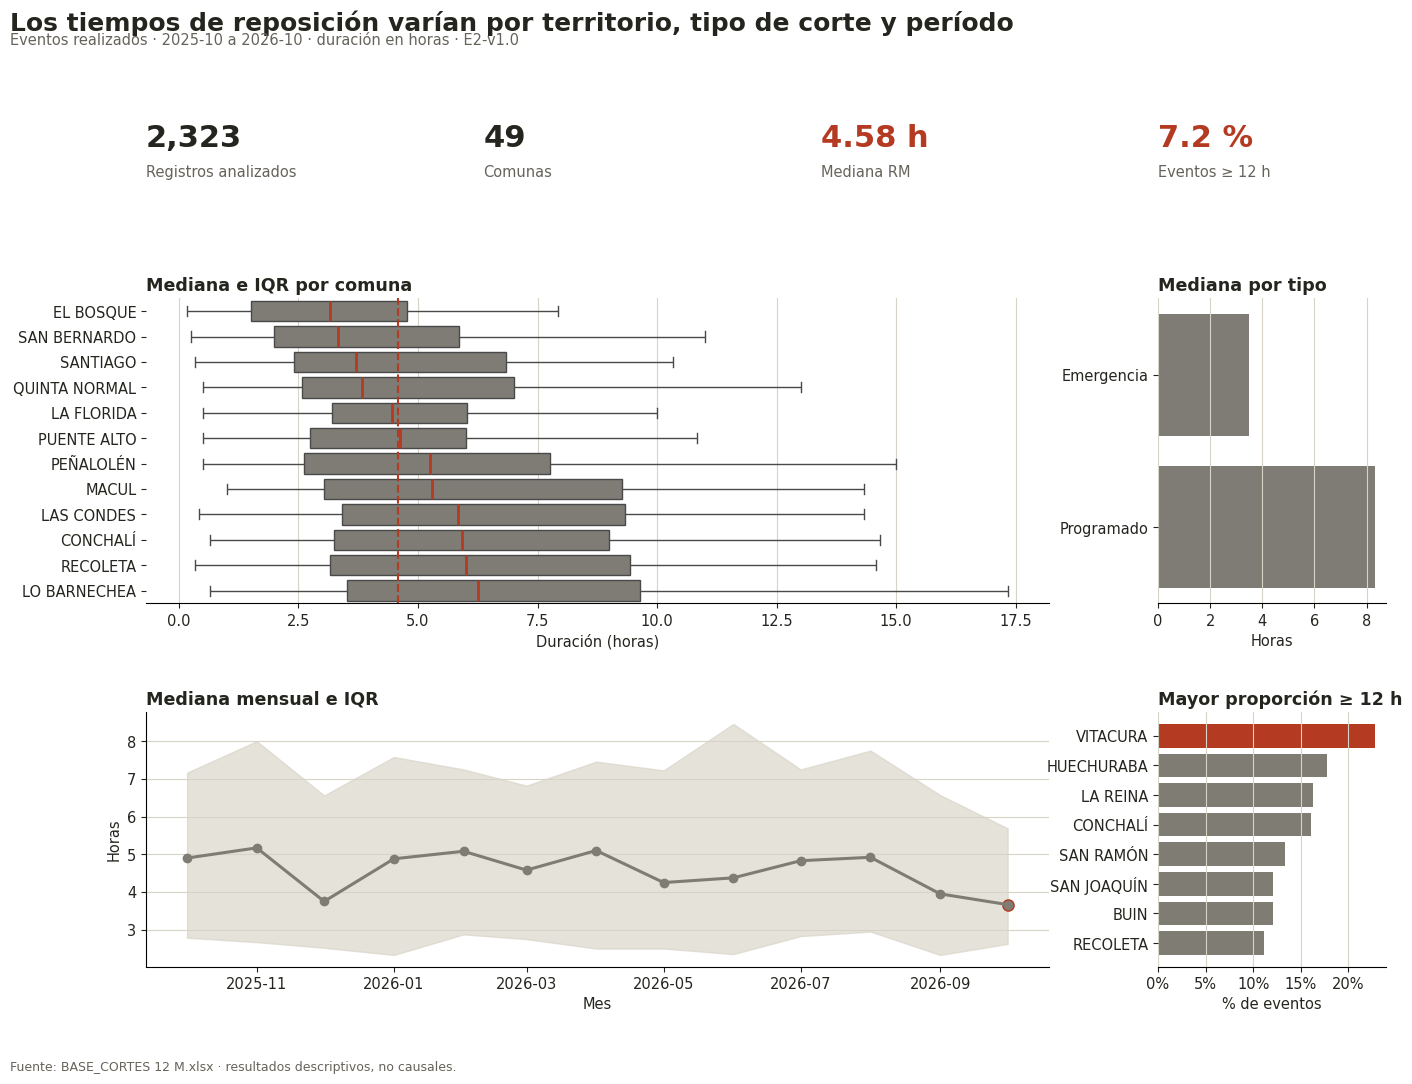

In [ ]:
fig=plt.figure(figsize=(16,11),facecolor="white"); gs=fig.add_gridspec(3,4,height_ratios=[.55,2.4,2],hspace=.52,wspace=.48)
fig.suptitle("Los tiempos de reposición varían por territorio, tipo de corte y período",x=.04,y=.98,ha="left",fontsize=18,fontweight="bold",color=INK)
fig.text(.04,.948,f"Eventos realizados · {universo.fecha_inicio} a {universo.fecha_fin} · duración en horas · {PIPELINE_VERSION}",color=MUTED)
kpis=[("Registros analizados",f"{len(df_clean):,}"),("Comunas",f"{df_clean.COMUNA.nunique():,}"),("Mediana RM",f"{df_clean.DURACION.median():.2f} h"),("Eventos ≥ 12 h",f"{df_clean.EVENTO_PROLONGADO_12H.mean()*100:.1f} %")]
for i,(lab,val) in enumerate(kpis):
 a=fig.add_subplot(gs[0,i]); a.axis("off"); a.text(0,.62,val,fontsize=22,fontweight="bold",color=ACC if i>1 else INK); a.text(0,.18,lab,color=MUTED)
a=fig.add_subplot(gs[1,:3]); sns.boxplot(data=plot_df,y="COMUNA",x="DURACION",order=orden,color=TAUPE,showfliers=False,medianprops={"color":ACC,"linewidth":2},ax=a); a.axvline(mediana_rm,color=ACC,ls="--"); a.set_title("Mediana e IQR por comuna",loc="left"); a.set(xlabel="Duración (horas)",ylabel=""); a.grid(axis="x",color=LIGHT); a.spines[["top","right","left"]].set_visible(False)
a=fig.add_subplot(gs[1,3]); sns.barplot(data=resumen_tipo,y="TIPO_CORTE",x="duracion_mediana_h",color=TAUPE,ax=a); a.set_title("Mediana por tipo",loc="left"); a.set(xlabel="Horas",ylabel=""); a.grid(axis="x",color=LIGHT); a.spines[["top","right","left"]].set_visible(False)
a=fig.add_subplot(gs[2,:3]); a.fill_between(x,resumen_mes.q1_h,resumen_mes.q3_h,color=LIGHT,alpha=.65); a.plot(x,resumen_mes.duracion_mediana_h,color=TAUPE,lw=2.2,marker="o"); a.scatter(resumen_mes.loc[imin,"FECHA_MES"],resumen_mes.loc[imin,"duracion_mediana_h"],color=ACC,s=65); a.set_title("Mediana mensual e IQR",loc="left"); a.set(xlabel="Mes",ylabel="Horas"); a.grid(axis="y",color=LIGHT); a.spines[["top","right"]].set_visible(False)
a=fig.add_subplot(gs[2,3]); long=resumen_comuna[resumen_comuna.n_eventos>=min_n].nlargest(8,"proporcion_12h_o_mas").sort_values("proporcion_12h_o_mas"); colors=[TAUPE]*len(long); colors[-1]=ACC if colors else ACC; a.barh(long.COMUNA,long.proporcion_12h_o_mas*100,color=colors); a.set_title("Mayor proporción ≥ 12 h",loc="left"); a.set(xlabel="% de eventos",ylabel=""); a.xaxis.set_major_formatter(mtick.PercentFormatter(100,0)); a.grid(axis="x",color=LIGHT); a.spines[["top","right","left"]].set_visible(False)
fig.text(.04,.015,"Fuente: BASE_CORTES 12 M.xlsx · resultados descriptivos, no causales.",fontsize=9,color=MUTED)
plt.savefig(OUTPUT_DIR/"prueba_concepto_e2.png",dpi=220,bbox_inches="tight",facecolor="white"); plt.show()


## 8. Exportación de respaldos y manifiesto

In [ ]:
with pd.ExcelWriter(OUTPUT_DIR/"tablas_analiticas_e2.xlsx",engine="openpyxl") as w:
 df_clean.to_excel(w,sheet_name="eventos_limpios",index=False); funnel.to_excel(w,sheet_name="funnel",index=False)
 estructura.to_excel(w,sheet_name="estructura",index=False); calidad.to_excel(w,sheet_name="calidad",index=False)
 resumen_comuna.to_excel(w,sheet_name="resumen_comuna",index=False); resumen_mes.to_excel(w,sheet_name="resumen_mes",index=False)
 resumen_tipo.to_excel(w,sheet_name="resumen_tipo",index=False); sensibilidad.to_excel(w,sheet_name="sensibilidad",index=False)
manifest={"pipeline_version":PIPELINE_VERSION,"run_timestamp":RUN_TIMESTAMP,"source_file":SOURCE_FILE.name,
"source_sha256":SOURCE_HASH,"source_rows":int(len(df_raw)),"analysis_rows":int(len(df_clean)),
"exact_duplicates_source":int(duplicado_exacto.sum()),"rules":["ESTADO = REALIZADO","DURACION > 0",
"COMUNA disponible","PERIODO válido","eliminación de duplicados exactos"],"controls":{k:bool(v) for k,v in controles.items()}}
with open(OUTPUT_DIR/"manifest_e2.json","w",encoding="utf-8") as f: json.dump(manifest,f,ensure_ascii=False,indent=2)
print("Salidas:"); [print("-",p.name) for p in sorted(OUTPUT_DIR.iterdir())]


Salidas:
- eda1_boxplot_comunas.png
- eda1_comuna_tipo.png
- eda2_promedio_vs_mediana.png
- eda2_serie_mensual.png
- manifest_e2.json
- prueba_concepto_e2.png
- tablas_analiticas_e2.xlsx


[None, None, None, None, None, None, None]

## 9. Registro de revisión E2

| Aspecto | Resultado esperado | Resultado observado | Acción / pendiente | Revisor |
|---|---|---|---|---|
| Representación | Paleta, títulos, unidades y significado del color consistentes | Completar | Corregir excepciones no justificadas | Integrante distinto del autor |
| Uso | Hallazgo identificable en 5 segundos y legible en notebook/proyector | Completar | Simplificar o aumentar legibilidad | Equipo |

**Conservar:** pregunta rectora, mediana e IQR, sistema visual L2 y límite no causal.  
**Revisar:** universo oficial, duplicados, cobertura mensual, tamaño muestral y sensibilidad del umbral.  
**Desarrollar después:** brief final, prueba visual refinada y registro de revisión.
